전체 행: 6168
원본 구간(in_span) 일수: 76
핵심 구간(use_core) 일수: 72


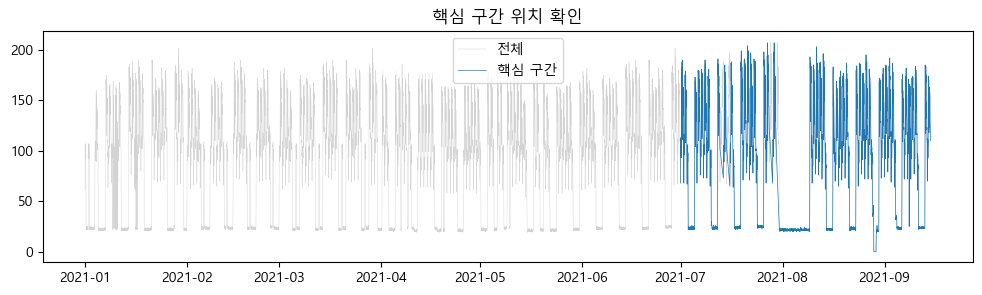

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

SEED = 42
np.random.seed(SEED)
for f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK JP']:
    if any(f == x.name for x in font_manager.fontManager.ttflist):
        plt.rcParams['font.family'] = f
        break
plt.rcParams['axes.unicode_minus'] = False

df = pd.read_csv('data/okm_augumented_2021.csv', encoding='utf-8-sig')
df['date'] = pd.to_datetime(df['날짜'].astype(str), format='%Y%m%d')
df['hour'] = df.groupby('날짜').cumcount()
df['ts'] = df['date'] + pd.to_timedelta(df['hour'], unit='h')

flags = pd.read_csv('results_ro/01_day_flags.csv')
df = df.merge(flags[['날짜', 'use_core', 'in_span']], on='날짜', how='left')

print('전체 행:', len(df))
print('원본 구간(in_span) 일수:', df.loc[df['in_span'], '날짜'].nunique())
print('핵심 구간(use_core) 일수:', df.loc[df['use_core'], '날짜'].nunique())

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(df['ts'], df['평균'], lw=0.3, color='lightgray', label='전체')
core = df[df['use_core']]
ax.plot(core['ts'], core['평균'], lw=0.5, color='tab:blue', label='핵심 구간')
ax.set_title('핵심 구간 위치 확인'); ax.legend()
plt.show()